# Pembuktian Soal Diskusi 4 – Regresi Berganda
**STIK4121 – Metode Statistik**

Notebook ini membuktikan jawaban setiap nomor (1–10) dengan perhitungan. Hanya memakai `numpy`, `pandas`, `scipy`, dan `matplotlib` (tanpa `statsmodels`), sehingga bisa dijalankan langsung di Jupyter/Colab.

In [ ]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
pd.set_option("display.precision", 4)

data = pd.DataFrame({
    "X1": [3,4,4,5,5,6,6,7,7,8,8,9,9,10,10],                    
    "X2": [8,10,12,13,15,16,18,20,21,23,24,26,28,30,32],        
    "X3": [60,62,65,68,70,72,74,76,78,80,82,84,86,88,90],       
    "Y":  [58,61,64,67,69,71,73,76,78,81,83,85,87,90,92],     
}, index=pd.RangeIndex(1, 16, name="No"))
data

,X1,X2,X3,Y
No,,,,
1,3,8,60,58
2,4,10,62,61
3,4,12,65,64
4,5,13,68,67
5,5,15,70,69
6,6,16,72,71
7,6,18,74,73
8,7,20,76,76
9,7,21,78,78


## No. 1 – Variabel respons
Variabel respons adalah variabel yang dijelaskan/diprediksi, yaitu **Nilai akhir (Y)**.

## No. 2 – Variabel prediktor

- X1 adalah jam belajar mandiri per minggu.
- X2 adalah jumlah akses tuton (LMS).
- X3 adalah nilai tugas tutorial.


## No. 3 – Mengapa regresi berganda, bukan sederhana?
Bukti: bandingkan regresi sederhana (satu X) dengan regresi berganda (tiga X). Koefisien regresi sederhana mencampur pengaruh X lain (karena saling berkorelasi), sedangkan regresi berganda memisahkan pengaruh tiap X dengan mengendalikan yang lain.

In [8]:
def ols(X, y):
    X = np.asarray(X, float); y = np.asarray(y, float)
    A = np.c_[np.ones(len(y)), X]
    b = np.linalg.solve(A.T @ A, A.T @ y)
    yhat = A @ b
    n, p = A.shape                      # p = k+1
    sse = ((y-yhat)**2).sum(); sst = ((y-y.mean())**2).sum(); ssr = sst-sse
    mse = sse/(n-p)
    cov = mse*np.linalg.inv(A.T @ A)
    se = np.sqrt(np.diag(cov)); t = b/se
    pval = 2*stats.t.sf(abs(t), n-p)
    r2 = 1-sse/sst; adj = 1-(1-r2)*(n-1)/(n-p)
    F = (ssr/(p-1))/mse; pF = stats.f.sf(F, p-1, n-p)
    return dict(b=b, se=se, t=t, p=pval, r2=r2, adj=adj, F=F, pF=pF, sse=sse, sst=sst, ssr=ssr,
                mse=mse, df=n-p, n=n, yhat=yhat, resid=y-yhat, cov=cov, A=A)

y = data["Y"].values
rows = []
for k in ["X1","X2","X3"]:
    m = ols(data[[k]], y)
    rows.append([f"Sederhana: Y~{k}", m["b"][1], m["r2"]])
mb = ols(data[["X1","X2","X3"]], y)
rows.append(["Berganda: b1 / b2 / b3", " / ".join(f"{v:.4f}" for v in mb["b"][1:]), mb["r2"]])
pd.DataFrame(rows, columns=["Model","Koefisien slope","R²"])

,Model,Koefisien slope,R²
0,Sederhana: Y~X1,4.7039,0.9888
1,Sederhana: Y~X2,1.4316,0.9954
2,Sederhana: Y~X3,1.1255,0.9985
3,Berganda: b1 / b2 / b3,0.6354 / 0.3208 / 0.7245,0.9994


Koefisien slope pada regresi sederhana berbeda jauh dari regresi berganda (mis. X₁: 4,70 vs 0,64) karena regresi sederhana menangkap pengaruh X₂ dan X₃ yang ikut naik bersama X₁. Regresi berganda memisahkan efek tiap variabel, sehingga lebih tepat.

## No. 4 – Pola data dan korelasi

         Y      X1      X2      X3
Y   1.0000  0.9944  0.9977  0.9993
X1  0.9944  1.0000  0.9918  0.9924
X2  0.9977  0.9918  1.0000  0.9964
X3  0.9993  0.9924  0.9964  1.0000


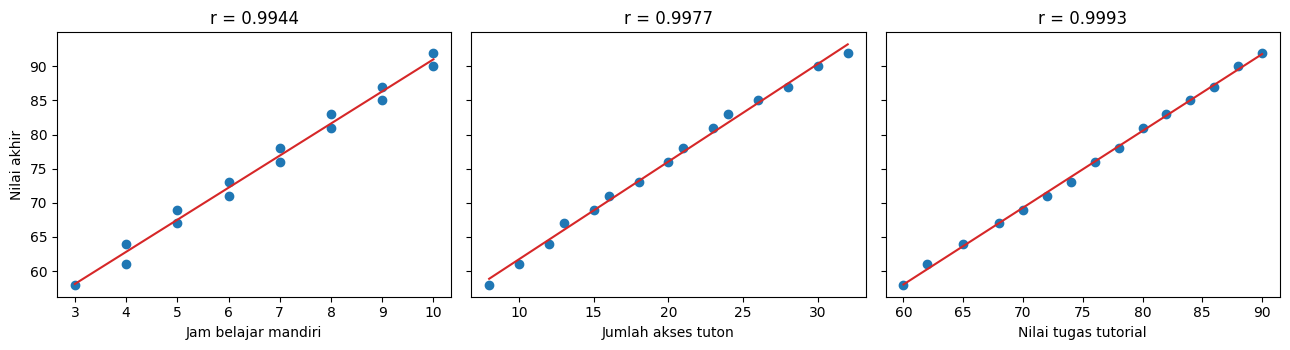

Y vs X1: r=0.9944, p-value=4.56e-14
Y vs X2: r=0.9977, p-value=1.43e-16
Y vs X3: r=0.9993, p-value=7.69e-20


In [9]:
corr = data[["Y","X1","X2","X3"]].corr()
display(corr) if "display" in globals() else print(corr)

fig, ax = plt.subplots(1,3, figsize=(13,3.6), sharey=True)
for a,k in zip(ax, ["X1","X2","X3"]):
    a.scatter(data[k], data["Y"]); 
    s,i = np.polyfit(data[k], data["Y"], 1); xs = np.linspace(data[k].min(), data[k].max(), 50)
    a.plot(xs, i+s*xs, color="tab:red"); a.set_xlabel(nama[k]); a.set_title(f"r = {corr.loc['Y',k]:.4f}")
ax[0].set_ylabel("Nilai akhir"); plt.tight_layout(); plt.show()

# Uji signifikansi korelasi
for k in ["X1","X2","X3"]:
    r,p = stats.pearsonr(data[k], data["Y"]); print(f"Y vs {k}: r={r:.4f}, p-value={p:.2e}")

**Kesimpulan:** ketiganya berkorelasi positif sangat kuat dan signifikan dengan Y (r > 0,99). Mahasiswa dengan jam belajar, akses tuton, dan nilai tugas lebih tinggi cenderung memiliki nilai akhir lebih tinggi.

## No. 5 – Estimasi a, b₁, b₂, b₃
Metode kuadrat terkecil (OLS): $\hat\beta=(X^TX)^{-1}X^Ty$.

In [10]:
X = data[["X1","X2","X3"]].values
m = ols(X, y)
tab = pd.DataFrame({"Koefisien": m["b"], "Std. Error": m["se"], "t": m["t"], "p-value": m["p"]},
                   index=["a (Intercept)","b1 (X1)","b2 (X2)","b3 (X3)"])
display(tab) if "display" in globals() else print(tab)
a,b1,b2,b3 = m["b"]
print(f"\nŶ = {a:.4f} + {b1:.4f} X1 + {b2:.4f} X2 + {b3:.4f} X3")

# Verifikasi dengan np.linalg.lstsq dan polyfit-independen
chk = np.linalg.lstsq(np.c_[np.ones(15), X], y, rcond=None)[0]
print("Cocok dengan lstsq:", np.allclose(chk, m["b"]))

# Kecocokan model
print(f"\nR² = {m['r2']:.4f} | Adj R² = {m['adj']:.4f} | F = {m['F']:.2f} (db 3,{m['df']}) | p = {m['pF']:.2e}")
anova = pd.DataFrame({"SS":[m["ssr"],m["sse"],m["sst"]], "db":[3,m["df"],14],
                      "MS":[m["ssr"]/3, m["mse"], np.nan]}, index=["Regresi","Galat","Total"])
display(anova) if "display" in globals() else print(anova)

               Koefisien  Std. Error       t     p-value
a (Intercept)    10.2406      5.4897  1.8654  8.9001e-02
b1 (X1)           0.6354      0.3065  2.0733  6.2421e-02
b2 (X2)           0.3208      0.1351  2.3740  3.6889e-02
b3 (X3)           0.7245      0.1101  6.5786  3.9778e-05

Ŷ = 10.2406 + 0.6354 X1 + 0.3208 X2 + 0.7245 X3
Cocok dengan lstsq: True

R² = 0.9994 | Adj R² = 0.9992 | F = 5710.80 (db 3,11) | p = 7.77e-18
                SS  db        MS
Regresi  1586.3148   3  528.7716
Galat       1.0185  11    0.0926
Total    1587.3333  14       NaN


## No. 6 – Interpretasi koefisien

In [11]:
names = nama
print(f"a  = {a:.4f}: nilai akhir prediksi bila X1=X2=X3=0 (hanya titik potong; di luar rentang data).")
print(f"b1 = {b1:.4f}: +1 jam belajar/minggu → nilai akhir naik ±{b1:.2f} poin (X2, X3 tetap).")
print(f"b2 = {b2:.4f}: +1 kali akses tuton → nilai akhir naik ±{b2:.2f} poin (X1, X3 tetap).")
print(f"b3 = {b3:.4f}: +1 poin nilai tugas → nilai akhir naik ±{b3:.2f} poin (X1, X2 tetap).")

# Bukti 'ceteris paribus': naikkan satu X sebesar 1, lainnya tetap
base = np.array([1,6,18,75.])
for i,(k,bk) in enumerate(zip(["X1","X2","X3"],[b1,b2,b3]), start=1):
    up = base.copy(); up[i]+=1
    print(f"Δŷ saat {k} +1 = {m['b']@up - m['b']@base:.4f}  (= b{i})")

# Koefisien baku (standardized beta) untuk membandingkan pengaruh relatif
beta_std = m["b"][1:]*X.std(0, ddof=1)/y.std(ddof=1)
print("\nKoefisien baku:", dict(zip(["X1","X2","X3"], beta_std.round(3).tolist())))

a  = 10.2406: nilai akhir prediksi bila X1=X2=X3=0 (hanya titik potong; di luar rentang data).
b1 = 0.6354: +1 jam belajar/minggu → nilai akhir naik ±0.64 poin (X2, X3 tetap).
b2 = 0.3208: +1 kali akses tuton → nilai akhir naik ±0.32 poin (X1, X3 tetap).
b3 = 0.7245: +1 poin nilai tugas → nilai akhir naik ±0.72 poin (X1, X2 tetap).
Δŷ saat X1 +1 = 0.6354  (= b1)
Δŷ saat X2 +1 = 0.3208  (= b2)
Δŷ saat X3 +1 = 0.7245  (= b3)

Koefisien baku: {'X1': 0.134, 'X2': 0.224, 'X3': 0.643}


## No. 7 – Prediksi: X₁ = 6, X₂ = 18, X₃ = 75

In [12]:
x0 = np.array([1, 6, 18, 75.])
yhat0 = x0 @ m["b"]
print(f"Ŷ = {a:.4f} + {b1:.4f}(6) + {b2:.4f}(18) + {b3:.4f}(75) = {yhat0:.2f}")

# Selang kepercayaan/prediksi 95%
tcrit = stats.t.ppf(0.975, m["df"])
se_mean = np.sqrt(x0 @ m["cov"] @ x0); se_pred = np.sqrt(m["mse"] + x0 @ m["cov"] @ x0)
print(f"CI 95% rata-rata : [{yhat0-tcrit*se_mean:.2f}, {yhat0+tcrit*se_mean:.2f}]")
print(f"PI 95% individu  : [{yhat0-tcrit*se_pred:.2f}, {yhat0+tcrit*se_pred:.2f}]")

Ŷ = 10.2406 + 0.6354(6) + 0.3208(18) + 0.7245(75) = 74.16
CI 95% rata-rata : [73.68, 74.64]
PI 95% individu  : [73.34, 74.99]


## No. 8 – Multikolinearitas
Bukti: (1) korelasi antar-X, (2) VIF, (3) condition number, (4) ketidakstabilan koefisien (leave-one-out) dan standard error besar.

In [13]:
# (1) Korelasi antar prediktor
print(data[["X1","X2","X3"]].corr().round(4))

# (2) VIF = 1/(1-R²_j), R²_j dari regresi Xj terhadap prediktor lain
vif = {}
for j,k in enumerate(["X1","X2","X3"]):
    others = [i for i in range(3) if i!=j]
    r2j = ols(X[:,others], X[:,j])["r2"]
    vif[k] = 1/(1-r2j)
print("\nVIF:", {k: round(float(v),1) for k,v in vif.items()}, "(> 10 → multikolinearitas serius)")

# (3) Condition number dari X yang diskalakan (kolom dinormalisasi)
Z = (X - X.mean(0))/X.std(0, ddof=1)
print("Condition number:", round(np.linalg.cond(Z),1), "(mendekati/ > 30 → indikasi masalah; VIF sudah jelas menunjukkan masalah)")

# (4) Ketidakstabilan: hapus satu observasi (leave-one-out)
loo = np.array([ols(np.delete(X,i,0), np.delete(y,i))["b"] for i in range(15)])
loo_df = pd.DataFrame({"Koef penuh": m["b"], "Min LOO": loo.min(0), "Maks LOO": loo.max(0),
                       "SE": m["se"]}, index=["a","b1","b2","b3"])
display(loo_df) if "display" in globals() else print(loo_df)

# Dampak: R² sangat tinggi tetapi SE koefisien besar → b1 dan b2 hanya signifikan tipis
print(f"\nR²={m['r2']:.4f}; p-value b1={m['p'][1]:.3f}, b2={m['p'][2]:.3f}, b3={m['p'][3]:.2e}")

# Contoh perbaikan: ridge regression pada data terstandarisasi
ys = (y-y.mean())/y.std(ddof=1)
for lam in [0, 0.1, 1, 10]:
    bz = np.linalg.solve(Z.T@Z + lam*np.eye(3), Z.T@ys)
    print(f"ridge λ={lam:>4}: koef baku =", bz.round(3))

        X1      X2      X3
X1  1.0000  0.9918  0.9924
X2  0.9918  1.0000  0.9964
X3  0.9924  0.9964  1.0000

VIF: {'X1': 71.9, 'X2': 152.0, 'X3': 163.9} (> 10 → multikolinearitas serius)
Condition number: 28.9 (mendekati/ > 30 → indikasi masalah; VIF sudah jelas menunjukkan masalah)
    Koef penuh  Min LOO  Maks LOO      SE
a      10.2406   7.7191   14.6457  5.4897
b1      0.6354   0.4799    0.7537  0.3065
b2      0.3208   0.2313    0.3971  0.1351
b3      0.7245   0.6364    0.7779  0.1101

R²=0.9994; p-value b1=0.062, b2=0.037, b3=3.98e-05
ridge λ=   0: koef baku = [0.134 0.224 0.643]
ridge λ= 0.1: koef baku = [0.223 0.32  0.455]
ridge λ=   1: koef baku = [0.304 0.328 0.347]
ridge λ=  10: koef baku = [0.267 0.27  0.272]


## No. 9 – Regresi ≠ sebab-akibat
Bukti: model regresi simetris secara statistik—kita bisa memprediksi arah mana pun dengan kecocokan sama baiknya, jadi hasil statistik saja tidak menentukan arah/sebab.

In [14]:
# (a) Arah dibalik: X3 (nilai tugas) diregresikan pada Y
rev = ols(data[["Y"]], data["X3"].values)
print(f"Regresi balik X3 ~ Y: R² = {rev['r2']:.4f} (sama kuatnya dengan Y ~ X3: {ols(data[['X3']], y)['r2']:.4f})")

# (b) Pengaruh variabel yang dihilangkan: koefisien X1 berubah drastis tergantung variabel lain
for cols in (["X1"], ["X1","X2"], ["X1","X2","X3"]):
    mm = ols(data[cols], y); print(f"b1 pada model {cols}: {mm['b'][1]:.4f}")

# (c) Semua variabel naik seiring urutan mahasiswa -> 'confounder' laten (mis. kemampuan/motivasi) tak terukur
print("\nKorelasi X1 dengan urutan mahasiswa:", round(np.corrcoef(np.arange(15), data['X1'])[0,1],4))

Regresi balik X3 ~ Y: R² = 0.9985 (sama kuatnya dengan Y ~ X3: 0.9985)
b1 pada model ['X1']: 4.7039
b1 pada model ['X1', 'X2']: 1.4103
b1 pada model ['X1', 'X2', 'X3']: 0.6354

Korelasi X1 dengan urutan mahasiswa: 0.9934


Koefisien b₁ berubah dari 4,70 (hanya X₁) menjadi 1,41 (X₁, X₂) lalu 0,64 (X₁, X₂, X₃) hanya karena variabel lain ditambahkan, sehingga nilainya tidak bisa dibaca sebagai efek kausal murni. Korelasi tinggi bisa muncul dari faktor lain yang tidak terukur (motivasi, kemampuan awal), arah hubungan yang terbalik, atau data observasional dengan n kecil.

## No. 10 – Pemanfaatan bagi tutor

Pengaruh relatif (koefisien baku):
Nilai tugas tutorial    0.643
Jumlah akses tuton      0.224
Jam belajar mandiri     0.134
dtype: float64

Mahasiswa no.1: prediksi saat ini = 58.18
  +2 jam belajar   → prediksi 59.45
  +8 akses tuton   → prediksi 60.75
  +5 nilai tugas   → prediksi 61.80

Mahasiswa berisiko (prediksi < 65):
    X1  X2  X3   Y  Prediksi
No                          
1    3   8  60  58   58.1809
2    4  10  62  61   60.9068
3    4  12  65  64   63.7217


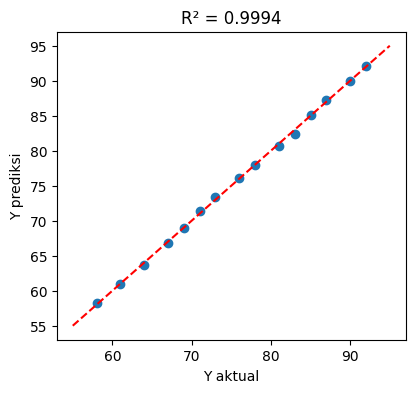

In [15]:
# (a) Faktor dengan pengaruh relatif terbesar (koefisien baku)
imp = pd.Series(beta_std, index=[nama[k] for k in ["X1","X2","X3"]]).sort_values(ascending=False)
print("Pengaruh relatif (koefisien baku):"); print(imp.round(3))

# (b) Skenario what-if: efek intervensi sederhana pada mahasiswa tertentu
mhs = data.iloc[[0]].copy()   # mahasiswa no. 1
base = m["b"] @ np.r_[1, mhs[["X1","X2","X3"]].values[0]]
skenario = {"+2 jam belajar": [2,0,0], "+8 akses tuton": [0,8,0], "+5 nilai tugas": [0,0,5]}
print(f"\nMahasiswa no.1: prediksi saat ini = {base:.2f}")
for s,d in skenario.items():
    print(f"  {s:<16} → prediksi {base + m['b'][1:]@np.array(d):.2f}")

# (c) Peringatan dini: mahasiswa dengan prediksi di bawah ambang (mis. < 65)
data["Prediksi"] = m["yhat"]
print("\nMahasiswa berisiko (prediksi < 65):"); print(data[data["Prediksi"]<65][["X1","X2","X3","Y","Prediksi"]])

# (d) Plot aktual vs prediksi
plt.figure(figsize=(4.5,4)); plt.scatter(y, m["yhat"]); plt.plot([55,95],[55,95],"r--")
plt.xlabel("Y aktual"); plt.ylabel("Y prediksi"); plt.title(f"R² = {m['r2']:.4f}"); plt.show()

**Ringkasan:** nilai tugas paling berasosiasi dengan nilai akhir, lalu jam belajar dan akses tuton. Tutor dapat memakai model untuk deteksi dini, memberi umpan balik tugas lebih kuat, dan mendorong keaktifan belajar. Interpretasikan sebagai asosiasi (lihat no. 9) dan waspadai multikolinearitas (no. 8).